In [ ]:
import pandas as pd

data_file = "final_performance.csv"
df = pd.read_csv(data_file)
df = df[df['blast_size']>= 100000]

df_1_minute = df[df['window_setting'].isin(["tumbling_1 minutes"])]
# df_2_minutes = df[df['window_setting'].isin(["sliding_2 minutes_1 minute"])]
df_5_minutes = df[df['window_setting'].isin(["tumbling_1 minutes", "sliding_5 minutes_0.5 minutes", "sliding_5 minutes_30 seconds", "sliding_5 minutes_2.5 minutes", "sliding_5 minutes_150 seconds"])]
df_10_minutes = df[df['window_setting'].isin(["tumbling_10 minutes", "sliding_10 minutes_5 minutes", "sliding_10 minutes_1 minutes"])]
df_30_minutes = df[df['window_setting'].isin(["tumbling_30 minutes", "sliding_30 minutes_15 minutes", "sliding_30 minutes_3 minutes"])]
df_60_minutes = df[df['window_setting'].isin(["tumbling_60 minutes",])]

print(f"Mean number of windows for 1-minute windows: {(df_1_minute['blast_size']/df_1_minute['number_of_windows']).mean()}")
print(f"Mean number of windows for 5-minute windows: {(df_5_minutes['blast_size']/df_5_minutes['number_of_windows']).mean()}")
print(f"Mean number of windows for 10-minute windows: {(df_10_minutes['blast_size']/df_10_minutes['number_of_windows']).mean()}")
print(f"Mean number of windows for 30-minute windows: {(df_30_minutes['blast_size']/df_30_minutes['number_of_windows']).mean()}")
print(f"Mean number of windows for 60-minute windows: {(df_60_minutes['blast_size']/df_60_minutes['number_of_windows']).mean()}")



Mean number of windows for 1-minute windows: 1783.933580849126
Mean number of windows for 5-minute windows: 2276.5046153644066
Mean number of windows for 10-minute windows: 5731.731431635543
Mean number of windows for 30-minute windows: 20035.405872840696
Mean number of windows for 60-minute windows: 45107.783265262064


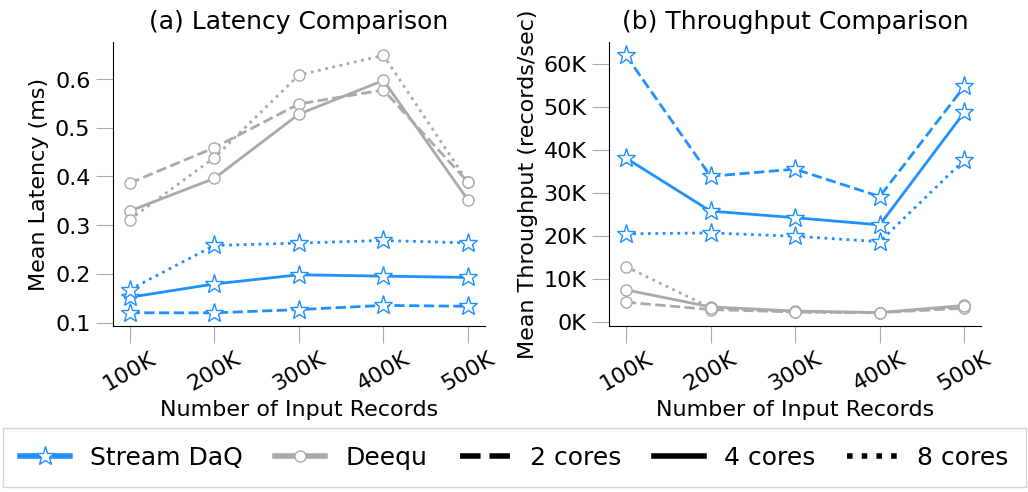

In [ ]:
#!/usr/bin/env python3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

###################################
# Global customization variables
###################################
# Figure size and font sizes
FIGSIZE = (10, 5)
AXIS_LABEL_SIZE = 16
TICKS_FONT_SIZE = 16
TITLE_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18

# Other style parameters
XTICK_ROTATION = 30
MARKER_FACE_COLOR = 'white'
LINE_WIDTH = 2
TICK_LENGTH = 12  # Increase this value if needed to make ticks clearly visible
TICK_COLOR = 'darkgray'
TICK_PADDING = 4

###################################
# Base plotting parameters per tool (color, label, marker and marker size)
###################################
plot_parameters = {
    'stream-daq': {
        "color": 'dodgerblue',
        "label": "Stream DaQ",
        "marker": "*",
        "marker_size": 14
    },
    'deequ': {
        "color": 'darkgray',
        "label": "Deequ",
        "marker": ".",
        "marker_size": 16
    }
}

###################################
# Define line styles based on the number of CPU cores.
###################################
line_styles = {
    2: '--',
    4: '-',
    8: ':'
}

###################################
# Data Preparation
###################################
data_file = "final_performance.csv"
df = pd.read_csv(data_file)

# Global filter: only consider rows with blast sizes of 100K and higher.
df = df[df['blast_size'] >= 100000]
# Filter for records with memory_limit '8G'
df = df[df['memory_limit'] == '12G']

# Filter for records from tumbling window 1 minute
df = df[df['window_setting'] == 'tumbling_1 minutes']
# df = df[df['window_setting'] == 'tumbling_10 minutes']
# df = df[df['window_setting'] == 'sliding_2 minutes_1 minute']
# df = df[df['window_setting'] == 'sliding_5 minutes_1 minute']
# df = df[df['window_setting'] == 'sliding_10 minutes_5 minute']


# Compute latency (sec) and throughput (records/sec)
df['latency'] = (df['max_timestamp'] - df['blast_start_time']).div(1000) / df['blast_size']
df['throughput'] = df['blast_size'] / (df['processing_time'] / 1000)

# Remove potentially corrupted records due to killed (out-of-memory) container
df = df[df['latency'] > 0]
df = df[df['throughput'] > 0]

###################################
# Create the figure and subplots
###################################
plt.figure(figsize=FIGSIZE)

###############################
# Subplot (a): Latency Comparison
###############################
plt.subplot(121)
plt.grid(False)

for tool in df['tool'].unique():
    tool_data = df[df['tool'] == tool].copy()
    for (memory, cores), group in tool_data.groupby(['memory_limit', 'number_of_cores']):
        # Compute mean latency per blast_size and sort by blast_size
        mean_latency = group.groupby('blast_size', as_index=False)['latency'].mean().sort_values('blast_size')
        label = f"{plot_parameters[tool]['label']} ({memory}, {cores} cores)"
        plt.plot(mean_latency['blast_size'], mean_latency['latency'],
                 linestyle=line_styles.get(cores, '-'),
                 marker=plot_parameters[tool]["marker"],
                 color=plot_parameters[tool]["color"],
                 markersize=plot_parameters[tool]["marker_size"],
                 linewidth=LINE_WIDTH,
                 label=label,
                 markerfacecolor=MARKER_FACE_COLOR)

plt.xlabel("Number of Input Records", fontsize=AXIS_LABEL_SIZE)
plt.ylabel("Mean Latency (ms)", fontsize=AXIS_LABEL_SIZE)
plt.title("(a) Latency Comparison", fontsize=TITLE_FONT_SIZE, pad=10)
plt.xticks(fontsize=TICKS_FONT_SIZE, rotation=XTICK_ROTATION)
plt.yticks(fontsize=TICKS_FONT_SIZE)

# Remove top and right spines and force tick marks outward on bottom and left
ax1 = plt.gca()
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.tick_params(axis='x', which='both', bottom=True, top=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
ax1.tick_params(axis='y', which='both', left=True, right=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
ax1.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}K'))
ax1.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'{round(y*1000, 3)}'))
# Set y-axis limit to maximum latency + 10 sec.
max_latency = df['latency'].max()
# ax1.set_ylim(0, max_latency + 10)

###############################
# Subplot (b): Throughput Comparison
###############################
plt.subplot(122)
plt.grid(False)

for tool in df['tool'].unique():
    tool_data = df[df['tool'] == tool].copy()
    for (memory, cores), group in tool_data.groupby(['memory_limit', 'number_of_cores']):
        mean_throughput = group.groupby('blast_size', as_index=False)['throughput'].mean().sort_values('blast_size')
        label = f"{plot_parameters[tool]['label']} ({memory}, {cores} cores)"
        plt.plot(mean_throughput['blast_size'], mean_throughput['throughput'],
                 linestyle=line_styles.get(cores, '-'),
                 marker=plot_parameters[tool]["marker"],
                 color=plot_parameters[tool]["color"],
                 markersize=plot_parameters[tool]["marker_size"],
                 linewidth=LINE_WIDTH,
                 label=label,
                 markerfacecolor=MARKER_FACE_COLOR)

plt.xlabel("Number of Input Records", fontsize=AXIS_LABEL_SIZE)
plt.ylabel("Mean Throughput (records/sec)", fontsize=AXIS_LABEL_SIZE)
plt.title("(b) Throughput Comparison", fontsize=TITLE_FONT_SIZE, pad=10)
plt.xticks(fontsize=TICKS_FONT_SIZE, rotation=XTICK_ROTATION)
plt.yticks(fontsize=TICKS_FONT_SIZE)

# Remove top and right spines and force tick marks outward for subplot (b)
ax2 = plt.gca()
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.tick_params(axis='x', which='both', bottom=True, top=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
ax2.tick_params(axis='y', which='both', left=True, right=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}K'))
ax2.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'{int(y/1000)}K'))

###################################
# Global legend: Combine handles for tools and CPU limits.
###################################
# Create legend handles for tools with markers.
tool_handles = [Line2D([0], [0],
                       marker=plot_parameters[tool]["marker"],
                       color=plot_parameters[tool]["color"],
                       markerfacecolor=MARKER_FACE_COLOR,
                       markersize=plot_parameters[tool]["marker_size"],
                       lw=4,
                       label=plot_parameters[tool]["label"])
                for tool in plot_parameters]

# Create legend handles for CPU configurations.
cpu_handles = [Line2D([0], [0], color='black',
                      linestyle=line_styles[cores],
                      lw=4,
                      label=f'{cores} cores')
                for cores in line_styles]

# Combine the legend handles; remove legend title and use a square frame.
all_handles = tool_handles + cpu_handles
legend = plt.gcf().legend(handles=all_handles, loc='lower center', ncol=len(all_handles),
                 fontsize=LEGEND_FONT_SIZE, columnspacing=1.3)
legend.set_title(None)
legend.get_frame().set_boxstyle("Square")

# Adjust horizontal spacing between subplots and bottom margin for the legend
plt.subplots_adjust(wspace=1, bottom=0.3)
plt.tight_layout(rect=[0, 0.12, 1, 1])

plt.savefig('throughput_latency_better.eps', format='eps', dpi=1000)
plt.show()

deequ 8G 4 0.48002479338842974
deequ 8G 8 0.5232950819672131
deequ 16G 4 0.3744297520661157
deequ 16G 8 0.2792892561983471
stream-daq 8G 4 0.034791946308724835
stream-daq 8G 8 0.04701020408163265
stream-daq 16G 4 0.03168070175438596
stream-daq 16G 8 0.031085011185682326
deequ 8G 4 0.7092739130434783
deequ 8G 8 0.9272857142857143
deequ 16G 4 0.5385862068965517
deequ 16G 8 0.3366341463414634
stream-daq 8G 4 0.11455555555555556
stream-daq 8G 8 0.1098
stream-daq 16G 4 0.09843333333333333
stream-daq 16G 8 0.08438888888888889
deequ 8G 4 0.7939473684210526
deequ 8G 8 1.156
deequ 16G 4 0.9352500000000001
deequ 16G 8 0.3163142857142857
stream-daq 8G 4 0
stream-daq 8G 8 0
stream-daq 16G 4 0
stream-daq 16G 8 0.5913333333333333
deequ 8G 4 0.5489444444444445
deequ 8G 8 0.5872682926829268
deequ 16G 4 0.686645945945946
deequ 16G 8 0.9228
stream-daq 8G 4 0.08110614525139666
stream-daq 8G 8 0.08293296089385475
stream-daq 16G 4 0.08337150837988827
stream-daq 16G 8 0.10903351955307262
deequ 8G 4 0.716888

<ipython-input-2-cc603746f8c4>:398: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.3, bottom=0.25)
<ipython-input-2-cc603746f8c4>:399: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0.14, 1, 1])


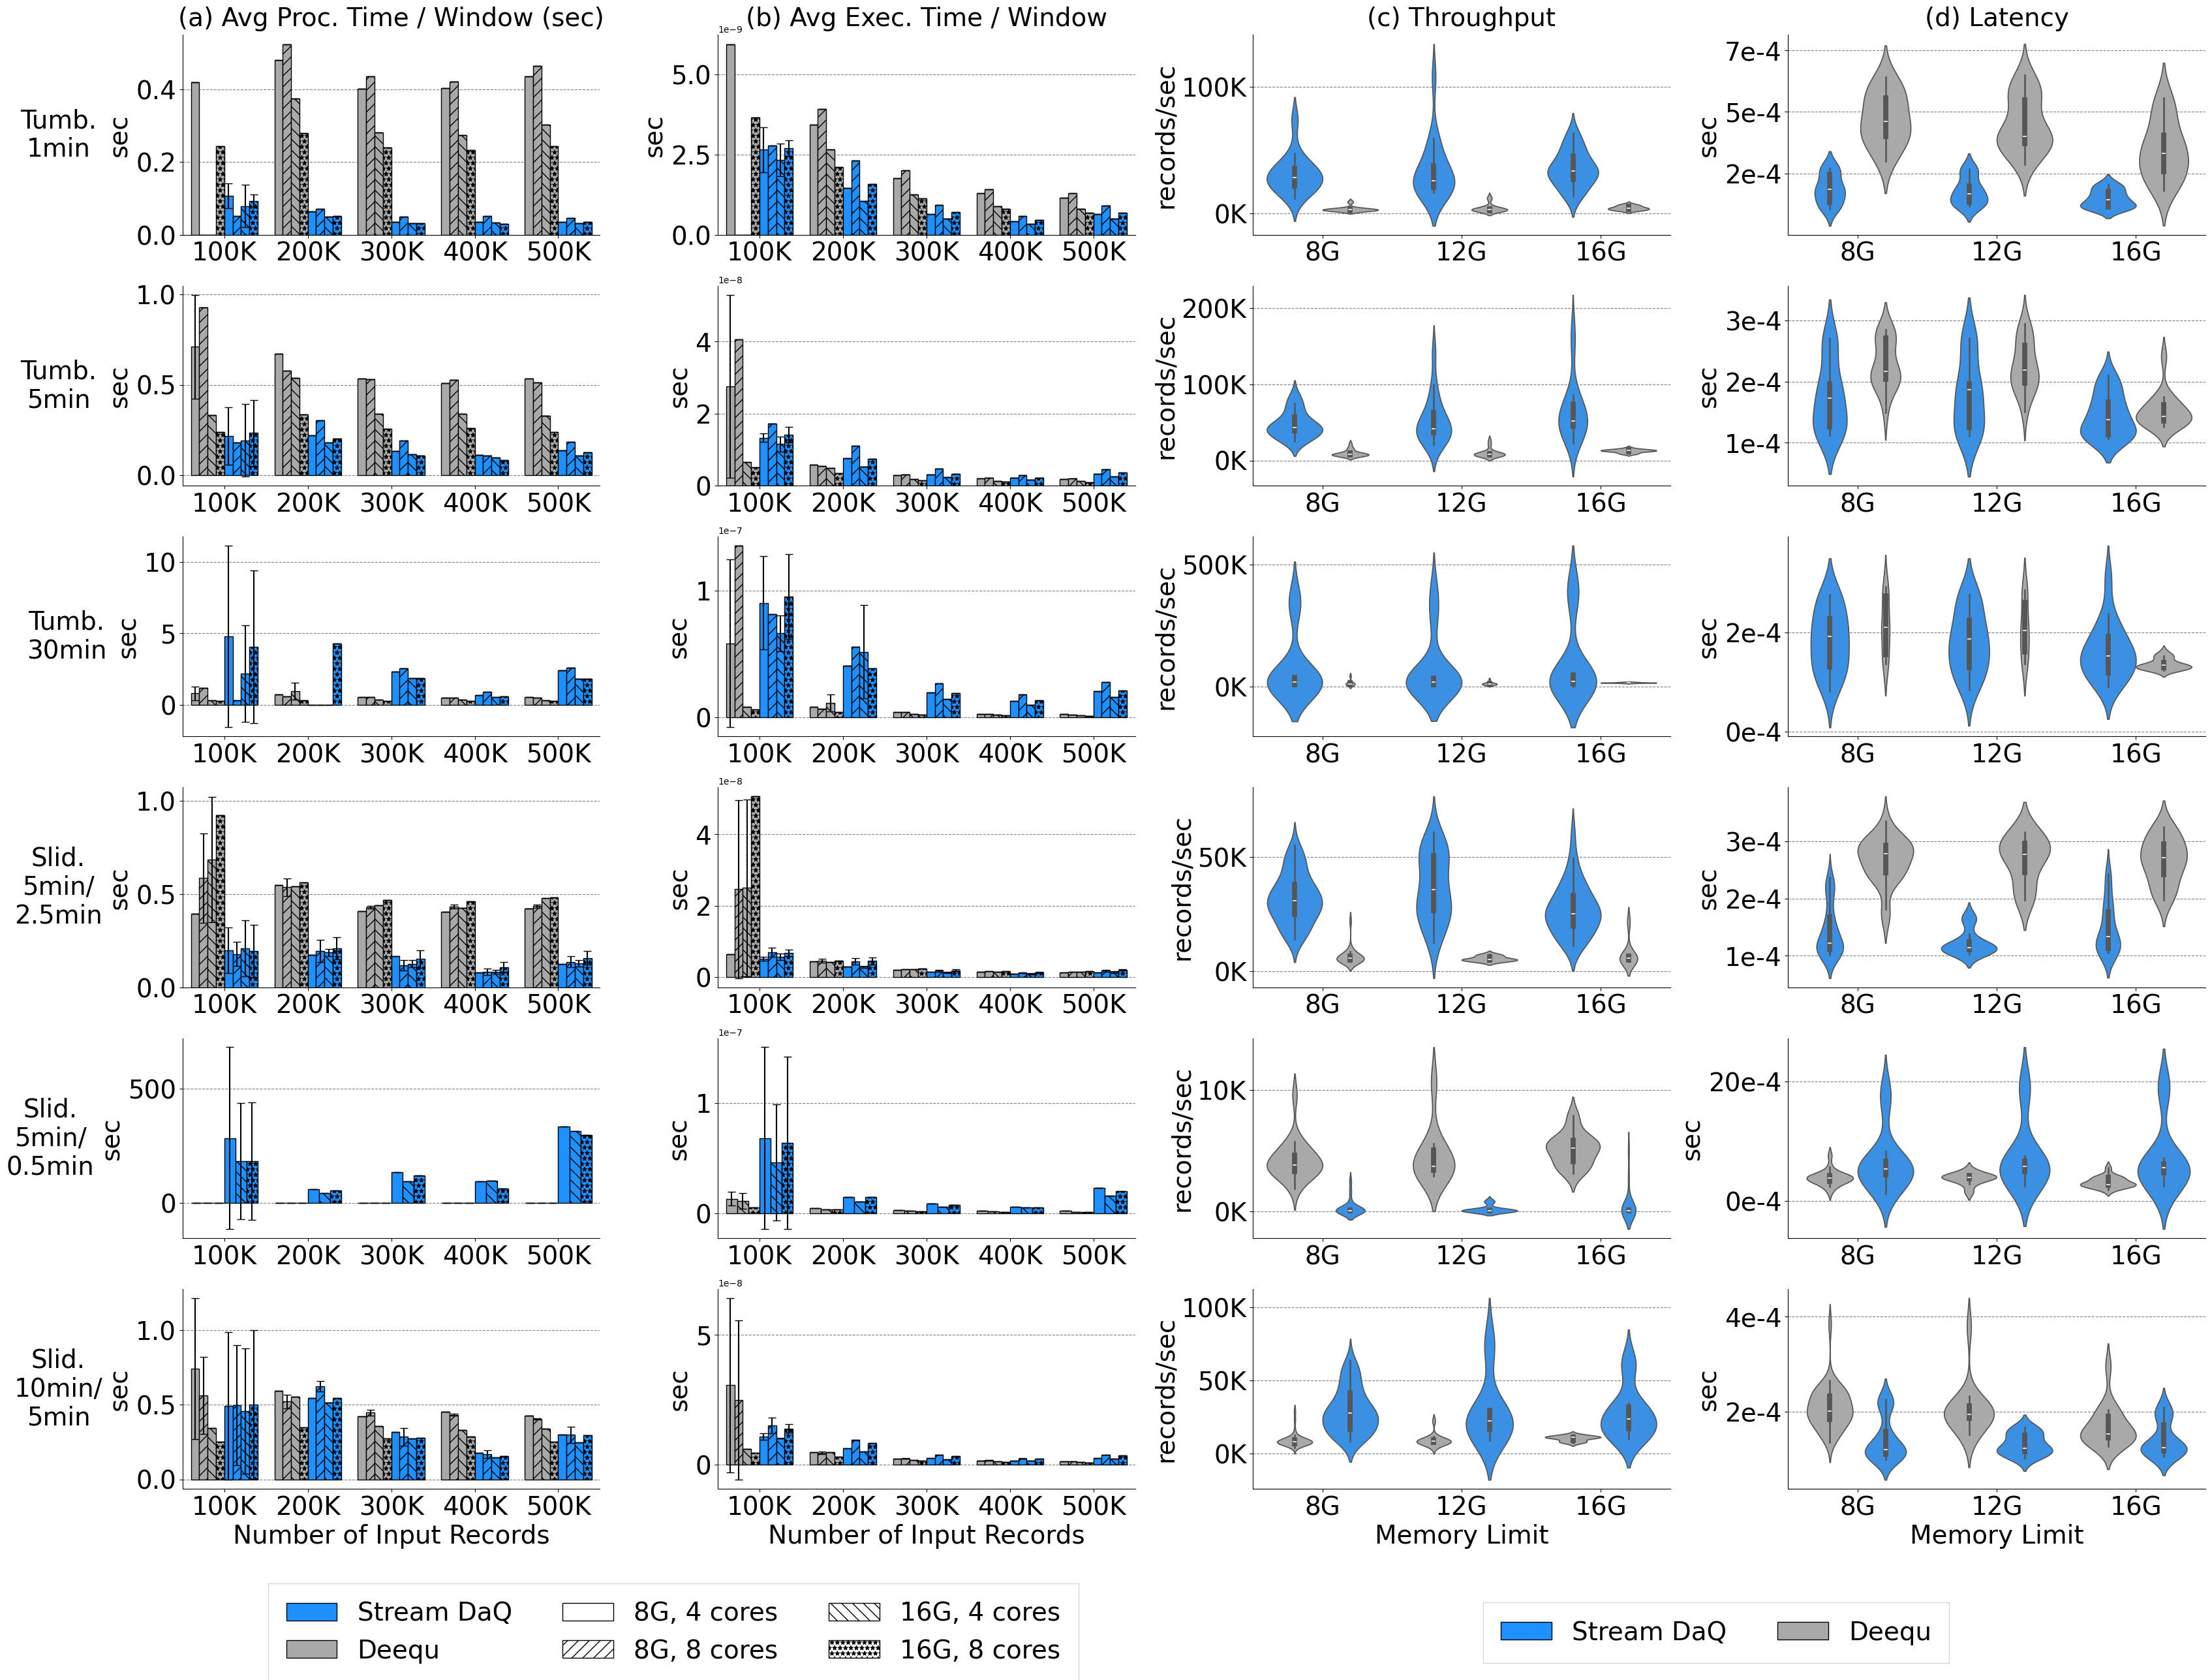

In [ ]:
#!/usr/bin/env python3
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter


def add_horizontal_grid(ax):
  COLOR='gray'
  LINESTYLE="dashed"

  ax.set_axisbelow(True)
  ax.yaxis.grid(color=COLOR, linestyle=LINESTYLE)


###################################
# Global customization variables
###################################
FIGSIZE = (34, 28)                  # 3 rowS x 4 columns grid
AXIS_LABEL_SIZE = 28
TICKS_FONT_SIZE = 28
TITLE_FONT_SIZE = 28
LEGEND_FONT_SIZE = 28

XTICK_ROTATION = 30
LINE_WIDTH = 2
TICK_LENGTH = 12
TICK_COLOR = 'darkgray'
TICK_PADDING = 4

BLAST_SIZE_BOX_PLOT = 300000

###################################
# Base plotting parameters per tool (color and label)
###################################
# Use dodgerblue for Stream DaQ and darkgray for Deequ.
plot_parameters = {
    'stream-daq': {
        "color": "dodgerblue",
        "label": "Stream DaQ"
    },
    'deequ': {
        "color": "darkgray",
        "label": "Deequ"
    }
}

###################################
# Define hatch patterns for each (memory_limit, number_of_cores) combination.
###################################
combo_patterns = {
    ("8G", 2): "",
    ("8G", 4): "",
    ("8G", 8): "//",
    ("12G", 2): "xx",
    ("12G", 4): "\\\\",
    ("12G", 8): "",
    ("16G", 2): "..",
    ("16G", 4): "\\\\",
    ("16G", 8): "**"
}
memory_order_all = ["8G", "12G", "16G"]
memory_order_bar_plots = ["8G", "16G"]
memory_order_violin_plots = ["8G", "12G", "16G"]
# memory_order = ["8G", "16G"]

windows_to_keep = [
    "tumbling_1 minutes",
    "tumbling_5 minutes",
    "tumbling_30 minutes",

]

WINDOWS_TO_PLOT = [
    "tumbling_1 minutes",
    "tumbling_5 minutes",
    "tumbling_30 minutes",
    "sliding_5 minutes_2.5 minutes",
    "sliding_30 minutes_3 minutes",
    "sliding_10 minutes_5 minutes",
]
ROW_NAMES = ["Tumb.\n1min",
             "Tumb.\n5min",
             "Tumb.\n30min",
             "Slid.\n5min/\n2.5min",
             "Slid.\n5min/\n0.5min",
             "Slid.\n10min/\n5min",
]

WINDOW_NAMES_TO_REPLACE = {
    'sliding_5 minutes_30 seconds': 'sliding_5 minutes_0.5 minutes',
    'sliding_5 minutes_150 seconds': 'sliding_5 minutes_2.5 minutes',
}

# cores_order = [2, 4, 8]
cores_order_all = [2, 4, 8]
cores_order_bar_plots = [4, 8]
cores_order_violin_plots = [2, 4, 8]

###################################
# Data Preparation
###################################
data_file = "final_performance.csv"
df = pd.read_csv(data_file)
df['latency'] = (df['max_timestamp'] - df['blast_start_time']).div(1000) / df['blast_size']
df['throughput'] = df['blast_size'] / (df['processing_time'] / 1000)

for name in WINDOW_NAMES_TO_REPLACE.keys():
  df = df.replace(name, WINDOW_NAMES_TO_REPLACE[name])
# df = df.replace('sliding_5 minutes_30 seconds', 'sliding_5 minutes_0.5 minutes')
# df = df.replace('sliding_5 minutes_150 seconds', 'sliding_5 minutes_2.5 minutes')

# Filter: only consider rows with blast sizes of 100K and higher.
df = df[df['blast_size'] >= 100000]
# Include only memory limits in our fixed order.
df = df[df['memory_limit'].isin(memory_order_all)]
# Focus on the two desired window configurations.
# df = df[df['window_setting'].isin(windows_to_keep)]
blast_sizes = [100000, 200000, 300000, 400000, 500000]
df = df[df['blast_size'].isin(blast_sizes)]
df = df[df['number_of_cores'].isin(cores_order_all)]

# Remove potentially corrupted records due to killed (out-of-memory) container
df = df[df['latency'] > 0]
df = df[df['throughput'] > 0]

# Compute average processing time per window (seconds)
df['proc_time_per_window'] = (df['processing_time'] / 1000) / df['number_of_windows']
# Compute average execution time per window (seconds)
df['exec_time_per_window'] = (df['latency'] / 1000) / df['number_of_windows']

###################################
# Group the data for bar plots (create separate groupings)
###################################
# Grouping for processing time (first subplot)
grouped_proc = df.groupby(["blast_size", "tool", "memory_limit", "number_of_cores", "window_setting"], as_index=False).agg(
    mean_exec_time=("proc_time_per_window", "mean"),
    std_exec_time=("proc_time_per_window", "std")
)

# Grouping for execution time (second subplot)
grouped_exec = df.groupby(["blast_size", "tool", "memory_limit", "number_of_cores", "window_setting"], as_index=False).agg(
    mean_exec_time=("exec_time_per_window", "mean"),
    std_exec_time=("exec_time_per_window", "std")
)

###################################
# Create figure with NUM_WINDOWS rows x 4 columns.
###################################
fig, axes = plt.subplots(nrows=len(WINDOWS_TO_PLOT), ncols=4, figsize=FIGSIZE, constrained_layout=True)
plt.setp(axes.flat, xlabel='', ylabel='')

pad = 50 # in points
for ax, row in zip(axes[:,0], ROW_NAMES):
    ax.annotate(row, xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - pad, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size=TITLE_FONT_SIZE, ha='center', va='center')

for window_idx, window_to_plot in enumerate(WINDOWS_TO_PLOT):
  ax_row = axes[window_idx]
  # ax_row.set_title(window_to_plot)
  ###################################
  # Subplot (a): Bar Plot for Tumbling Window (tumbling_1 minute) - Processing Time per Window
  ##################################
  ax = ax_row[0]
  tumbling_data = grouped_proc[grouped_proc["window_setting"] == window_to_plot]
  if window_idx == 2:
    tumbling_data = tumbling_data[tumbling_data["mean_exec_time"] < 5]
  tumbling_data = tumbling_data[tumbling_data['number_of_cores'].isin(cores_order_bar_plots)]
  tumbling_data = tumbling_data[tumbling_data['memory_limit'].isin(memory_order_bar_plots)]
  # tumbling_data = grouped_proc[grouped_proc["window_setting"] == "tumbling_10 minutes"]
  # tumbling_data = grouped_proc[grouped_proc["window_setting"] == "sliding_5 minutes_1 minute"]
  # tumbling_data = grouped_proc[grouped_proc["window_setting"] == "sliding_10 minutes_5 minute"]

  # Get unique combinations, order them by tool then by memory (fixed order) then CPU.
  combos_tumbling = tumbling_data[['tool', 'memory_limit', 'number_of_cores']].drop_duplicates().values.tolist()
  combos_tumbling = sorted(combos_tumbling, key=lambda x: (x[0], memory_order_bar_plots.index(x[1]), x[2]))
  n_combos = len(combos_tumbling)

  group_width = 0.8
  bar_width = group_width / n_combos
  indices = np.arange(len(blast_sizes))

  for i, (tool, mem, cores) in enumerate(combos_tumbling):
      subset = tumbling_data[
          (tumbling_data["tool"] == tool) & (tumbling_data["memory_limit"] == mem) &
          (tumbling_data["number_of_cores"] == cores)
      ]
      y_means = []
      y_stds = []
      for bs in blast_sizes:
          rec = subset[subset["blast_size"] == bs]
          if not rec.empty:
              y_means.append(rec["mean_exec_time"].values[0])
              y_stds.append(rec["std_exec_time"].values[0] if not np.isnan(rec["std_exec_time"].values[0]) else 0)
          else:
              y_means.append(0)
              y_stds.append(0)
      offset = (i - (n_combos - 1) / 2) * bar_width
      x_pos = indices + offset
      hatch = combo_patterns.get((mem, cores), "")
      color = plot_parameters[tool]["color"]
      label = f"{plot_parameters[tool]['label']} | {mem}, {cores} cores"
      ax.bar(x_pos, y_means, width=bar_width, yerr=y_stds, capsize=4,
            color=color, hatch=hatch, edgecolor="black", label=label)
      print(tool, mem, cores, max(y_means) if tool=='deequ' else min(y_means))

  ax.set_xticks(indices)
  ax.set_xticklabels([f"{int(bs/1000)}K" for bs in blast_sizes], fontsize=TICKS_FONT_SIZE)
  if window_idx == len(WINDOWS_TO_PLOT) - 1: # add x label only to the last row
    ax.set_xlabel("Number of Input Records", fontsize=AXIS_LABEL_SIZE)
  else:
    ax.set_xlabel(None, fontsize=AXIS_LABEL_SIZE)
  ax.set_ylabel("sec", fontsize=AXIS_LABEL_SIZE)
  if window_idx == 0: # add column title only to the first row
    ax.set_title("(a) Avg Proc. Time / Window (sec)", fontsize=TITLE_FONT_SIZE, pad=10)
  ax.tick_params(axis="y", labelsize=TICKS_FONT_SIZE)
  ax.set_xlim(-0.5, len(blast_sizes) - 0.5)
  # Remove top and right spines.
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  add_horizontal_grid(ax)

  ###################################
  # Subplot (b): Bar Plot for Sliding Window (sliding_5 minutes_1 minute) - Execution Time per Window
  ###################################
  ax = ax_row[1]
  sliding_data = grouped_exec[grouped_exec["window_setting"] == window_to_plot]
  # sliding_data = grouped_exec[grouped_exec["window_setting"] == "sliding_2 minutes_1 minute"]
  # sliding_data = grouped_exec[grouped_exec["window_setting"] == "sliding_5 minutes_1 minute"]
  # sliding_data = grouped_exec[grouped_exec["window_setting"] == "sliding_10 minutes_5 minute"]
  # sliding_data = grouped_exec[grouped_exec["window_setting"] == "tumbling_10 minutes"]

  sliding_data = sliding_data[sliding_data['memory_limit'].isin(memory_order_bar_plots)]
  sliding_data = sliding_data[sliding_data['number_of_cores'].isin(cores_order_bar_plots)]
  combos_sliding = sliding_data[['tool', 'memory_limit', 'number_of_cores']].drop_duplicates().values.tolist()
  combos_sliding = sorted(combos_sliding, key=lambda x: (x[0], memory_order_bar_plots.index(x[1]), x[2]))
  n_combos_sliding = len(combos_sliding)
  bar_width = group_width / n_combos_sliding
  indices = np.arange(len(blast_sizes))

  for i, (tool, mem, cores) in enumerate(combos_sliding):
      subset = sliding_data[
          (sliding_data["tool"] == tool) & (sliding_data["memory_limit"] == mem) &
          (sliding_data["number_of_cores"] == cores)
      ]
      y_means = []
      y_stds = []
      for bs in blast_sizes:
          rec = subset[subset["blast_size"] == bs]
          if not rec.empty:
              y_means.append(rec["mean_exec_time"].values[0])
              y_stds.append(rec["std_exec_time"].values[0] if not np.isnan(rec["std_exec_time"].values[0]) else 0)
          else:
              y_means.append(0)
              y_stds.append(0)
      offset = (i - (n_combos_sliding - 1) / 2) * bar_width
      x_pos = indices + offset
      hatch = combo_patterns.get((mem, cores), "")
      color = plot_parameters[tool]["color"]
      label = f"{plot_parameters[tool]['label']} | {mem}, {cores} cores"
      ax.bar(x_pos, y_means, width=bar_width, yerr=y_stds, capsize=4,
            color=color, hatch=hatch, edgecolor="black", label=label)

  ax.set_xticks(indices)
  ax.set_xticklabels([f"{int(bs/1000)}K" for bs in blast_sizes], fontsize=TICKS_FONT_SIZE)
  if window_idx == len(WINDOWS_TO_PLOT) - 1:
    ax.set_xlabel("Number of Input Records", fontsize=AXIS_LABEL_SIZE)
  else:
    ax.set_xlabel(None, fontsize=AXIS_LABEL_SIZE)
  ax.set_ylabel("sec", fontsize=AXIS_LABEL_SIZE)
  if window_idx == 0:
    ax.set_title("(b) Avg Exec. Time / Window", fontsize=TITLE_FONT_SIZE, pad=10)
  ax.tick_params(axis="y", labelsize=TICKS_FONT_SIZE)
  ax.set_xlim(-0.5, len(blast_sizes) - 0.5)
  # Remove top and right spines.
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  add_horizontal_grid(ax)

  #########################################################################
  # Subplot (c): Boxplot for Tumbling Window (tumbling_1 minute) - Throughput Distribution by Memory Limit
  #########################################################################
  # For the scatter/boxplot subplots, we restrict data to 4 cores.
  df_box_tumbling = df[(df["window_setting"]==window_to_plot)].copy()
  # df_box_tumbling = df[(df["window_setting"]=="tumbling_10 minutes")].copy()
  # df_box_tumbling = df_box_tumbling[df_box_tumbling["blast_size"] == BLAST_SIZE_BOX_PLOT]

  # print(list(df_box_tumbling[df_box_tumbling['tool'] =='stream-daq']["throughput"]))



  # Using seaborn's boxplot; x-axis = memory_limit, y-axis = throughput, hue = tool.
  ax = ax_row[2]
  sns.violinplot(x="memory_limit", y="throughput", hue="tool", data=df_box_tumbling,
              order=memory_order_violin_plots,
              palette={ "stream-daq": plot_parameters["stream-daq"]["color"],
                        "deequ": plot_parameters["deequ"]["color"]},
              ax=ax)
  if window_idx == len(WINDOWS_TO_PLOT) - 1:
    ax.set_xlabel("Memory Limit", fontsize=AXIS_LABEL_SIZE)
  else:
    ax.set_xlabel(None, fontsize=AXIS_LABEL_SIZE)
  ax.set_ylabel("records/sec", fontsize=AXIS_LABEL_SIZE)
  if window_idx == 0:
    ax.set_title("(c) Throughput", fontsize=TITLE_FONT_SIZE, pad=10)
  ax.tick_params(axis="both", labelsize=TICKS_FONT_SIZE)
  ax.get_yaxis().set_major_formatter(FuncFormatter(lambda x, p: f"{int(x/1000)}K"))
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  # Remove the default legend from this subplot.
  if ax.get_legend():
    ax.get_legend().remove()
  add_horizontal_grid(ax)

  #########################################################################
  # Subplot (d): Boxplot for Sliding Window (sliding_2 minutes_1 minute) - Throughput Distribution by Memory Limit
  #########################################################################
  # df_box_sliding = df[(df["window_setting"]=="sliding_5 minutes_1 minute") & (df["number_of_cores"]==4)].copy()
  # df_box_sliding = df[(df["window_setting"]=="sliding_10 minutes_5 minute")].copy()
  df_box_sliding = df[(df["window_setting"]==window_to_plot) & (df['latency'] > 0.00008)].copy()
  # df_box_sliding = df_box_sliding[df_box_sliding["blast_size"] == BLAST_SIZE_BOX_PLOT]
  ax = ax_row[3]
  sns.violinplot(x="memory_limit", y="latency", hue="tool", data=df_box_sliding,
              order=memory_order_violin_plots,
              palette={ "stream-daq": plot_parameters["stream-daq"]["color"],
                        "deequ": plot_parameters["deequ"]["color"]},
              ax=ax)
  if window_idx == len(WINDOWS_TO_PLOT) - 1:
    ax.set_xlabel("Memory Limit", fontsize=AXIS_LABEL_SIZE)
  else:
    ax.set_xlabel(None, fontsize=AXIS_LABEL_SIZE)
  ax.set_ylabel("sec", fontsize=AXIS_LABEL_SIZE)
  if window_idx == 0:
    ax.set_title("(d) Latency", fontsize=TITLE_FONT_SIZE, pad=10)
  ax.tick_params(axis="both", labelsize=TICKS_FONT_SIZE)
  # ax.get_yaxis().set_major_formatter(FuncFormatter(lambda x, p: f"{round(x*1000, 2)}")) # Important: This makes the y-axis in milliseconds, so the label needs to be updated!
  ax.get_yaxis().set_major_formatter(FuncFormatter(lambda x, p: f"{int(x*10000)}e-4"))
  ax.spines["top"].set_visible(False)
  ax.spines["right"].set_visible(False)
  add_horizontal_grid(ax)

  ax.get_legend().remove()

ax = axes[-1]
###################################
# Global Legend for Subplots (a) and (b)
###################################
# We want the legend to have:
# 1. Tool indicator: a colored rectangle for each tool.
# 2. Pattern indicator: a rectangle with white background and hatch for each memory/CPU combination.
tool_handles = []
for tool, props in plot_parameters.items():
    rect = plt.Rectangle((0, 0), 1, 1, facecolor=props["color"], edgecolor="black")
    tool_handles.append((rect, props["label"]))

# For pattern indicator, enforce memory order and CPU 2 then 4.
pattern_combos = []
for mem in memory_order_bar_plots:
    for cores in cores_order_bar_plots:
        pattern_combos.append((mem, cores))
pattern_handles = []
for mem, cores in pattern_combos:
    hatch = combo_patterns.get((mem, cores), "")
    rect = plt.Rectangle((0, 0), 1, 1, facecolor="white", edgecolor="black", hatch=hatch)
    label = f"{mem}, {cores} cores"
    pattern_handles.append((rect, label))
all_handles = [h for h, l in tool_handles] + [h for h, l in pattern_handles]
all_labels  = [l for h, l in tool_handles] + [l for h, l in pattern_handles]

# Center legend for subplots (a) and (b) only.
legend = plt.gcf().legend(all_handles, all_labels, loc="lower center", ncol=3, fontsize=LEGEND_FONT_SIZE,
                          # bbox_to_anchor=(0.30, 0.03, 0.01,0),
                          bbox_to_anchor=(0.30, 0.07, 0.01,0),
                          bbox_transform=plt.gcf().transFigure, frameon=True)
legend.set_title(None)
legend.get_frame().set_boxstyle("Square")

#########################################################################
# Global Legend for Subplots (c) and (d)
#########################################################################
# We want the legend to show tool colors:
legend_handles = []
for tool, props in plot_parameters.items():
    patch = Patch(facecolor=props["color"], edgecolor="black", label=props["label"])
    legend_handles.append(patch)

global_legend_c_d = plt.gcf().legend(legend_handles, [props["label"] for props in plot_parameters.values()],
                                 loc="lower center", ncol=2, fontsize=LEGEND_FONT_SIZE,
                                #  bbox_to_anchor=(0.25, 0.05, 1.05, 0),
                                 bbox_to_anchor=(0.25, 0.08, 1.05, 0),
                                     bbox_transform=plt.gcf().transFigure, frameon=True)
global_legend_c_d.set_title(None)
global_legend_c_d.get_frame().set_boxstyle("Square")

plt.subplots_adjust(wspace=0.3, bottom=0.25)
plt.tight_layout(rect=[0, 0.14, 1, 1])
plt.savefig(f"comparison_grid_6x4_all.pdf", format="pdf", dpi=1000, bbox_extra_artists=(legend, global_legend_c_d))
# plt.savefig(f"comparison_grid_6x4_all.svg", format="svg", dpi=1000, bbox_extra_artists=(legend, global_legend_c_d), bbox_inches="tight")
# plt.savefig(f"comparison_grid_1x4_{WINDOW_TO_PLOT}.svg", format="svg", bbox_extra_artists=(legend, global_legend_c_d), bbox_inches='tight')
plt.show()

<ipython-input-3-c8b921435d93>:244: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(wspace=0.05, bottom=0, hspace=0)
<ipython-input-3-c8b921435d93>:245: UserWarning: The figure layout has changed to tight
  plt.tight_layout(rect=[0, 0.07, 1, 1])


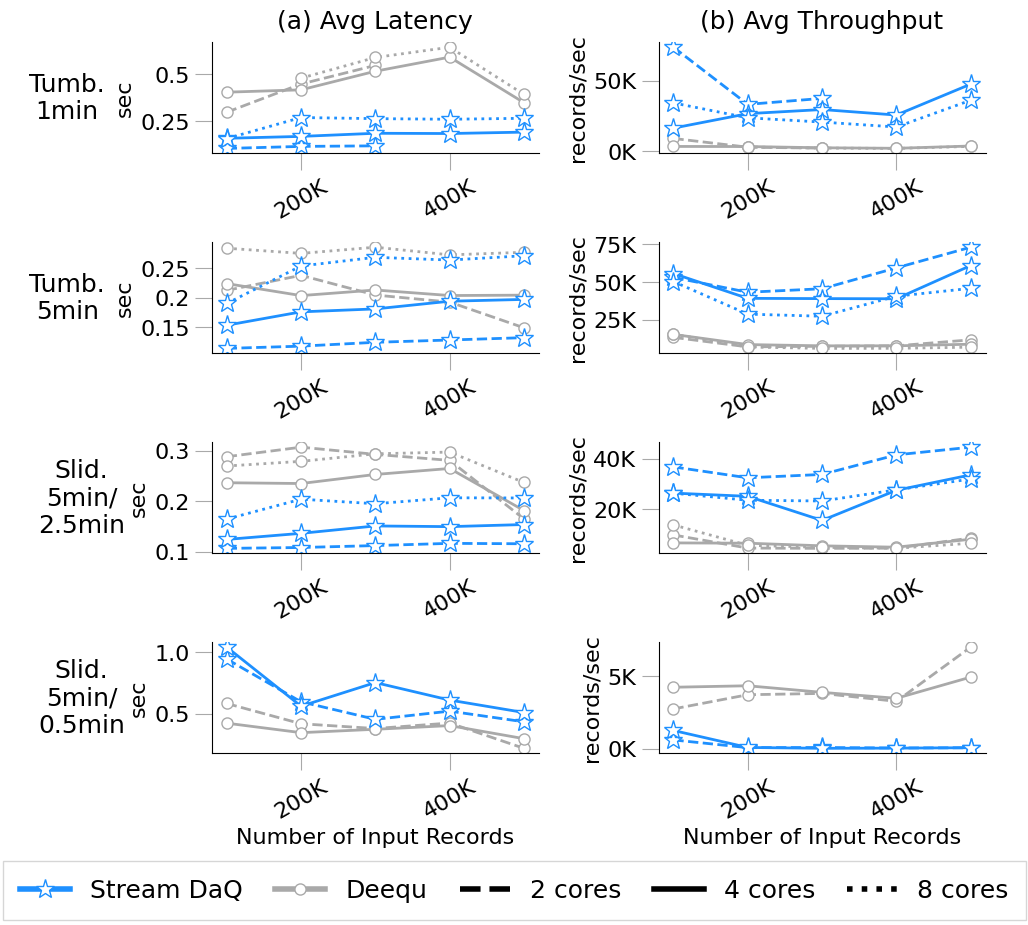

In [ ]:
#!/usr/bin/env python3
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

###################################
# Global customization variables
###################################
# Figure size and font sizes

AXIS_LABEL_SIZE = 16
TICKS_FONT_SIZE = 16
TITLE_FONT_SIZE = 18
LEGEND_FONT_SIZE = 18

# Other style parameters
XTICK_ROTATION = 30
MARKER_FACE_COLOR = 'white'
LINE_WIDTH = 2
TICK_LENGTH = 12  # Increase this value if needed to make ticks clearly visible
TICK_COLOR = 'darkgray'
TICK_PADDING = 4


###################################
# Base plotting parameters per tool (color, label, marker and marker size)
###################################
plot_parameters = {
    'stream-daq': {
        "color": 'dodgerblue',
        "label": "Stream DaQ",
        "marker": "*",
        "marker_size": 14
    },
    'deequ': {
        "color": 'darkgray',
        "label": "Deequ",
        "marker": ".",
        "marker_size": 16
    }
}

###################################
# Define line styles based on the number of CPU cores.
###################################
line_styles = {
    2: '--',
    4: '-',
    8: ':'
}


WINDOWS_TO_PLOT = [
    "tumbling_1 minutes",
    "tumbling_5 minutes",
    # "tumbling_30 minutes",
    "sliding_5 minutes_2.5 minutes",
    "sliding_30 minutes_3 minutes",
    # "sliding_10 minutes_5 minutes",
]
ROW_NAMES = [
    "Tumb.\n1min",
    "Tumb.\n5min",
    # "Tumb.\n30min",
    "Slid.\n5min/\n2.5min",
    "Slid.\n5min/\n0.5min",
    # "Slid.\n10min/\n5min",
]

FIGSIZE = (10, 2.333 * len(ROW_NAMES))

WINDOW_NAMES_TO_REPLACE = {
    'sliding_5 minutes_30 seconds': 'sliding_5 minutes_0.5 minutes',
    'sliding_5 minutes_150 seconds': 'sliding_5 minutes_2.5 minutes',
}

###################################
# Data Preparation
###################################
data_file = "final_performance.csv"
df = pd.read_csv(data_file)

for name in WINDOW_NAMES_TO_REPLACE.keys():
  df = df.replace(name, WINDOW_NAMES_TO_REPLACE[name])

# Global filter: only consider rows with blast sizes of 100K and higher.
df = df[df['blast_size'] >= 100000]
# Filter for records with memory_limit '8G'
df = df[df['memory_limit'] == '8G']

# Filter for records from tumbling window 1 minute
# df = df[df['window_setting'] == 'tumbling_1 minutes']
# df = df[df['window_setting'] == 'tumbling_10 minutes']
# df = df[df['window_setting'] == 'sliding_2 minutes_1 minute']
# df = df[df['window_setting'] == 'sliding_5 minutes_1 minute']
# df = df[df['window_setting'] == 'sliding_10 minutes_5 minute']


# Compute latency (sec) and throughput (records/sec)
df['latency'] = (df['max_timestamp'] - df['blast_start_time']).div(1000) / df['blast_size']
df['throughput'] = df['blast_size'] / (df['processing_time'] / 1000)

# Remove potentially corrupted records due to killed (out-of-memory) container
df = df[df['latency'] > 0]
df = df[df['throughput'] > 0]

###################################
# Create the figure and subplots
###################################
fig, axes = plt.subplots(nrows=len(WINDOWS_TO_PLOT), ncols=2, figsize=FIGSIZE, constrained_layout=True)
plt.setp(axes.flat, xlabel='', ylabel='')

pad = 30 # in points
for ax, row in zip(axes[:,0], ROW_NAMES):
    ax.annotate(row, xy=(0, 0.5), xytext=(-ax.yaxis.labelpad - pad, 0),
                xycoords=ax.yaxis.label, textcoords='offset points',
                size=TITLE_FONT_SIZE, ha='center', va='center')


for window_idx, window_to_plot in enumerate(WINDOWS_TO_PLOT):
  ax_row = axes[window_idx]

  ###############################
  # Subplot (a): Latency Comparison
  ###############################
  ax = ax_row[0]
  df_latency = df[(df["window_setting"]==window_to_plot)].copy()
  # plt.subplot(121)
  ax.grid(False)

  for tool in df['tool'].unique():
      tool_data = df_latency[df_latency['tool'] == tool].copy()
      for (memory, cores), group in tool_data.groupby(['memory_limit', 'number_of_cores']):
          # Compute mean latency per blast_size and sort by blast_size
          mean_latency = group.groupby('blast_size', as_index=False)['latency'].mean().sort_values('blast_size')
          label = f"{plot_parameters[tool]['label']} ({memory}, {cores} cores)"
          ax.plot(mean_latency['blast_size'], mean_latency['latency'],
                  linestyle=line_styles.get(cores, '-'),
                  marker=plot_parameters[tool]["marker"],
                  color=plot_parameters[tool]["color"],
                  markersize=plot_parameters[tool]["marker_size"],
                  linewidth=LINE_WIDTH,
                  label=label,
                  markerfacecolor=MARKER_FACE_COLOR)

  if window_idx == len(WINDOWS_TO_PLOT) - 1:
    ax.set_xlabel("Number of Input Records", fontsize=AXIS_LABEL_SIZE)
  else:
    ax.set_xlabel(None, fontsize=AXIS_LABEL_SIZE)

  ax.tick_params(axis="both", labelsize=TICKS_FONT_SIZE)
  ax.tick_params(axis="x", rotation=XTICK_ROTATION)
  ax.set_ylabel("sec", fontsize=AXIS_LABEL_SIZE)
  if window_idx == 0:
    ax.set_title("(a) Avg Latency", fontsize=TITLE_FONT_SIZE, pad=10)
  # ax.set_xticks(fontsize=TICKS_FONT_SIZE, rotation=XTICK_ROTATION)
  # ax.set_yticks(fontsize=TICKS_FONT_SIZE)

  # Remove top and right spines and force tick marks outward on bottom and left
  ax1 = plt.gca()
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.tick_params(axis='x', which='both', bottom=True, top=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
  ax.tick_params(axis='y', which='both', left=True, right=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
  ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}K'))
  ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'{round(y*1000, 3)}'))
  # Set y-axis limit to maximum latency + 10 sec.
  max_latency = df['latency'].max()
  # ax.set_ylim(0, max_latency + 10)

  ###############################
  # Subplot (b): Throughput Comparison
  ###############################
  ax = ax_row[1]
  df_throughput = df[(df["window_setting"]==window_to_plot)].copy()
  # plt.subplot(122)
  ax.grid(False)

  for tool in df['tool'].unique():
      tool_data = df_throughput[df_throughput['tool'] == tool].copy()
      for (memory, cores), group in tool_data.groupby(['memory_limit', 'number_of_cores']):
          mean_throughput = group.groupby('blast_size', as_index=False)['throughput'].mean().sort_values('blast_size')
          label = f"{plot_parameters[tool]['label']} ({memory}, {cores} cores)"
          ax.plot(mean_throughput['blast_size'], mean_throughput['throughput'],
                  linestyle=line_styles.get(cores, '-'),
                  marker=plot_parameters[tool]["marker"],
                  color=plot_parameters[tool]["color"],
                  markersize=plot_parameters[tool]["marker_size"],
                  linewidth=LINE_WIDTH,
                  label=label,
                  markerfacecolor=MARKER_FACE_COLOR)

  if window_idx == len(WINDOWS_TO_PLOT) - 1:
    ax.set_xlabel("Number of Input Records", fontsize=AXIS_LABEL_SIZE)
  else:
    ax.set_xlabel(None, fontsize=AXIS_LABEL_SIZE)
  ax.tick_params(axis="both", labelsize=TICKS_FONT_SIZE)
  ax.tick_params(axis="x", rotation=XTICK_ROTATION)
  ax.set_ylabel("records/sec", fontsize=AXIS_LABEL_SIZE)
  if window_idx == 0:
    ax.set_title("(b) Avg Throughput", fontsize=TITLE_FONT_SIZE, pad=10)
  # ax.set_xticks(fontsize=TICKS_FONT_SIZE, rotation=XTICK_ROTATION)
  # ax.set_yticks(fontsize=TICKS_FONT_SIZE)


  # Remove top and right spines and force tick marks outward for subplot (b)
  ax2 = plt.gca()
  ax.spines['top'].set_visible(False)
  ax.spines['right'].set_visible(False)
  ax.tick_params(axis='x', which='both', bottom=True, top=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
  ax.tick_params(axis='y', which='both', left=True, right=False, direction='out', length=TICK_LENGTH, pad=TICK_PADDING, color=TICK_COLOR)
  ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{int(x/1000)}K'))
  ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, pos: f'{int(y/1000)}K'))

###################################
# Global legend: Combine handles for tools and CPU limits.
###################################
# Create legend handles for tools with markers.
tool_handles = [Line2D([0], [0],
                       marker=plot_parameters[tool]["marker"],
                       color=plot_parameters[tool]["color"],
                       markerfacecolor=MARKER_FACE_COLOR,
                       markersize=plot_parameters[tool]["marker_size"],
                       lw=4,
                       label=plot_parameters[tool]["label"])
                for tool in plot_parameters]

# Create legend handles for CPU configurations.
cpu_handles = [Line2D([0], [0], color='black',
                      linestyle=line_styles[cores],
                      lw=4,
                      label=f'{cores} cores')
                for cores in line_styles]

# Combine the legend handles; remove legend title and use a square frame.
all_handles = tool_handles + cpu_handles
legend = plt.gcf().legend(handles=all_handles, loc='lower center', ncol=len(all_handles),
                 fontsize=LEGEND_FONT_SIZE, columnspacing=1.3)
legend.set_title(None)
legend.get_frame().set_boxstyle("Square")

# Adjust horizontal spacing between subplots and bottom margin for the legend
plt.subplots_adjust(wspace=0.05, bottom=0, hspace=0)
plt.tight_layout(rect=[0, 0.07, 1, 1])

plt.savefig('throughput_latency_grid.pdf', format='pdf', dpi=1000, bbox_inches="tight")
plt.show()